In [148]:
import pandas as pd 
import numpy as np
file_path = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
df_cus = pd.read_csv(file_path)
print("The data is successfully uploaded.")

The data is successfully uploaded.


In [149]:
df_cus.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [150]:
print(df_cus.columns)

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')


In [151]:
print(f'Dataset shape: \nRows: {df_cus.shape[0]} \nColumns: {df_cus.shape[1]}')

Dataset shape: 
Rows: 7043 
Columns: 21


In [152]:
print("\nData types:")
print(df_cus.dtypes)


Data types:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


In [153]:
# Checking the missing values 
df_cus.isnull().sum()

df_cus = df_cus.dropna()

print(df_cus.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [154]:
print(f'Duplicates: {df_cus.duplicated().sum()}')

Duplicates: 0


In [155]:
# Convert TotalCharges to numeric
df_cus["TotalCharges"] = pd.to_numeric(
    df_cus["TotalCharges"],
    errors="coerce"
)
print("TotalCharges data type:", df_cus["TotalCharges"].dtype)

TotalCharges data type: float64


In [156]:
print(df_cus["TotalCharges"].isnull().sum())

11


In [157]:
df_cus[df_cus["TotalCharges"].isnull()][
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


In [158]:
# Fill missing TotalCharges for new customers with 0
df_cus["TotalCharges"] = df_cus["TotalCharges"].fillna(0)
print(
    f"The missing values: "
    f"{df_cus["TotalCharges"].isnull().sum()}"
)

The missing values: 0


In [159]:
# Statistical summary
df_cus.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.00,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.734304,2266.794470,0.00,398.55,1394.55,3786.60,8684.80


In [161]:
# Binary churn variable for calculations
df_cus["Churn_Flag"] = df_cus["Churn"].map({"Yes": 1, "No": 0}).astype("int8")

# Customer lifetime / tenure groups
df_cus["Tenure_Group"] = pd.cut(
    df_cus["tenure"],
    bins=[-1, 12, 24, 36, 48, 60, 72],
    labels=[
        "0-12 months",
        "13-24 months",
        "25-36 months",
        "37-48 months",
        "49-60 months",
        "61-72 months"
    ],
    include_lowest=True
)

# Monthly charge groups
charge_bins = [-0.01, 40, 70, 100, np.inf]
charge_labels = [
    "$0–$40",
    "$41–$70",
    "$71–$100",
    "$100+"
]


df_cus["Monthly_Charge_Group"] = pd.cut(
    df_cus["MonthlyCharges"],
    bins=charge_bins,
    labels=charge_labels,
    include_lowest=True
)

print(df_cus[["Churn", "Churn_Flag", "Tenure_Group", "Monthly_Charge_Group"]].head())

  Churn  Churn_Flag  Tenure_Group Monthly_Charge_Group
0    No           0   0-12 months               $0–$40
1    No           0  25-36 months              $41–$70
2   Yes           1   0-12 months              $41–$70
3    No           0  37-48 months              $41–$70
4   Yes           1   0-12 months             $71–$100


In [162]:
total_customers = len(df_cus)
churned_customers = int(df_cus["Churn_Flag"].sum())
overall_churn_rate = df_cus["Churn_Flag"].mean() * 100
retention_rate = 100 - overall_churn_rate

churn_summary = pd.DataFrame({
    "Customer_Status": ["Churned", "Retained"],
    "Customer_Count": [
        churned_customers,
        total_customers - churned_customers
    ]
})
churn_summary["Percentage"] = (
    churn_summary["Customer_Count"] / total_customers * 100
).round(2)

print(f"Total customers: {total_customers:,}")
print(f"Churned customers: {churned_customers:,}")
print(f"Overall churn rate: {overall_churn_rate:.2f}%")
print(f"Retention rate: {retention_rate:.2f}%")

display(churn_summary)

Total customers: 7,043
Churned customers: 1,869
Overall churn rate: 26.54%
Retention rate: 73.46%


,Customer_Status,Customer_Count,Percentage
0,Churned,1869,26.54
1,Retained,5174,73.46


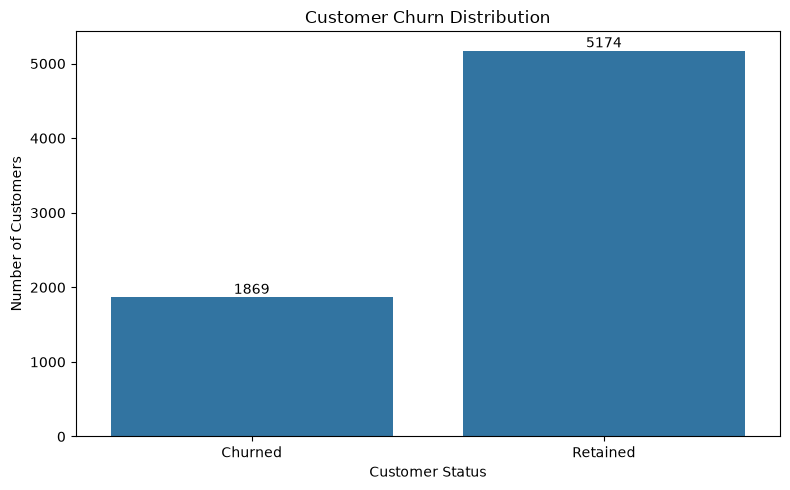

In [163]:
import matplotlib.pyplot as plt
import seaborn as sns 

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=churn_summary,
    x="Customer_Status",
    y="Customer_Count",

)

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container, fmt="%d")

plt.tight_layout()
plt.show()

In [164]:
tenure_summary = (
    df_cus.groupby("Tenure_Group", observed=False)
    .agg(
        Customers=("customerID", "count"),
        Churned=("Churn_Flag", "sum"),
        Churn_Rate=("Churn_Flag", "mean")
    )
)

tenure_summary["Churn_Rate"] = (tenure_summary["Churn_Rate"] * 100).round(2)

display(tenure_summary)

print("\nTenure statistics:")
print(f"Minimum tenure: {df_cus['tenure'].min()} months")
print(f"Maximum tenure: {df_cus['tenure'].max()} months")
print(f"Average tenure: {df_cus['tenure'].mean():.2f} months")
print(f"Median tenure: {df_cus['tenure'].median():.2f} months")

,Customers,Churned,Churn_Rate
Tenure_Group,,,
0-12 months,2186,1037,47.44
13-24 months,1024,294,28.71
25-36 months,832,180,21.63
37-48 months,762,145,19.03
49-60 months,832,120,14.42
61-72 months,1407,93,6.61



Tenure statistics:
Minimum tenure: 0 months
Maximum tenure: 72 months
Average tenure: 32.37 months
Median tenure: 29.00 months


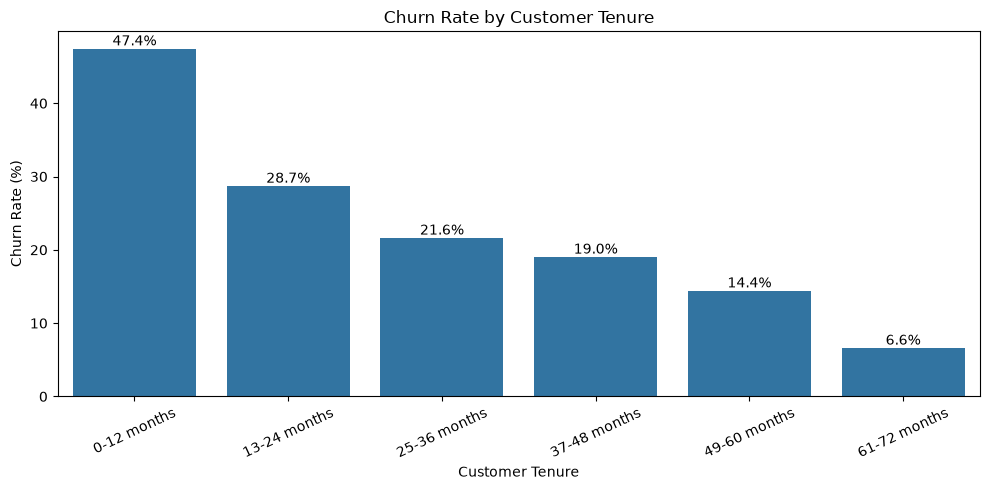

In [165]:
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=tenure_summary.reset_index(),
    x="Tenure_Group",
    y="Churn_Rate"
)

plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=25)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.tight_layout()
plt.show()

In [169]:
contract_summary = (
    df_cus.groupby("Contract")
    .agg(
        Customers=("customerID", "count"),
        Churned=("Churn_Flag", "sum"),
        Churn_Rate=("Churn_Flag", "mean")
    )
)

contract_summary["Churn_Rate"] = (contract_summary["Churn_Rate"] * 100).round(2)
contract_summary = contract_summary.sort_values("Churn_Rate", ascending=False)

print(contract_summary)

                Customers  Churned  Churn_Rate
Contract                                      
Month-to-month       3875     1655       42.71
One year             1473      166       11.27
Two year             1695       48        2.83


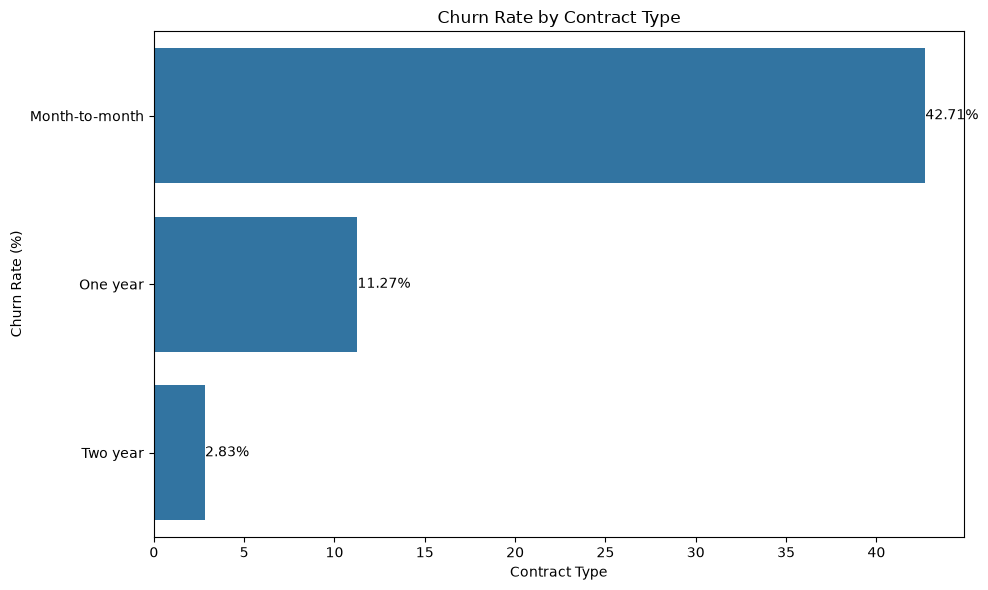

In [170]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=contract_churn.values,
    y=contract_churn.index
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.tight_layout()
plt.show()

In [171]:
# Select categorical variables 
categorical_features = [
    "PaymentMethod",
    "InternetService",
    "SeniorCitizen",
    "TechSupport",
    "OnlineSecurity",
    "PaperlessBilling"
]

for feature in categorical_features:
    if feature in df_cus.columns:
        print(f"\nChurn rate by {feature}:")

        summary = (
            df_cus.groupby(feature, dropna=False)["Churn_Flag"]
            .agg(["count", "mean"])
            .rename(columns={
                "count": "Customers",
                "mean": "Churn_Rate"
            })
        )
        
        summary["Churn_Rate"] = (
            summary["Churn_Rate"] * 100
        ).round(2)

        display(summary.sort_values(
            "Churn_Rate", ascending=False
        ))


Churn rate by PaymentMethod:


,Customers,Churn_Rate
PaymentMethod,,
Electronic check,2365,45.29
Mailed check,1612,19.11
Bank transfer (automatic),1544,16.71
Credit card (automatic),1522,15.24



Churn rate by InternetService:


,Customers,Churn_Rate
InternetService,,
Fiber optic,3096,41.89
DSL,2421,18.96
No,1526,7.40



Churn rate by SeniorCitizen:


,Customers,Churn_Rate
SeniorCitizen,,
1,1142,41.68
0,5901,23.61


... (2 outputs left out)


Churn rate by OnlineSecurity:


,Customers,Churn_Rate
OnlineSecurity,,
No,3498,41.77
Yes,2019,14.61
No internet service,1526,7.40



Churn rate by PaperlessBilling:


,Customers,Churn_Rate
PaperlessBilling,,
Yes,4171,33.57
No,2872,16.33


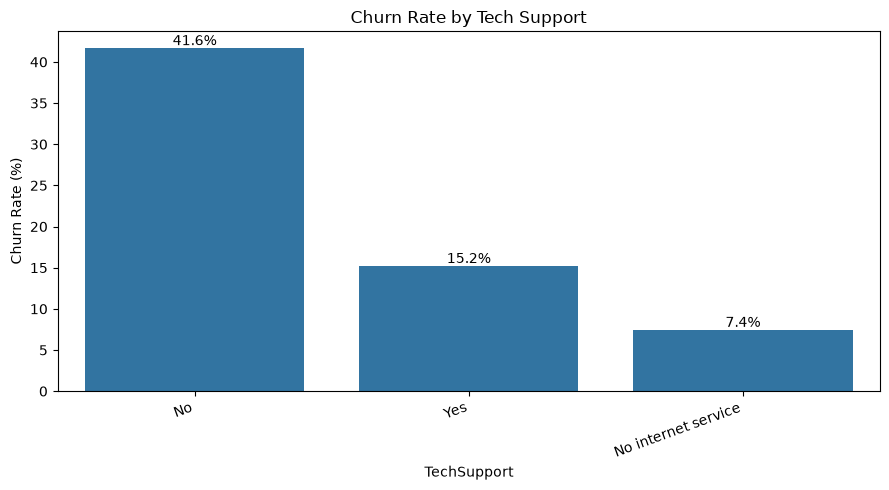

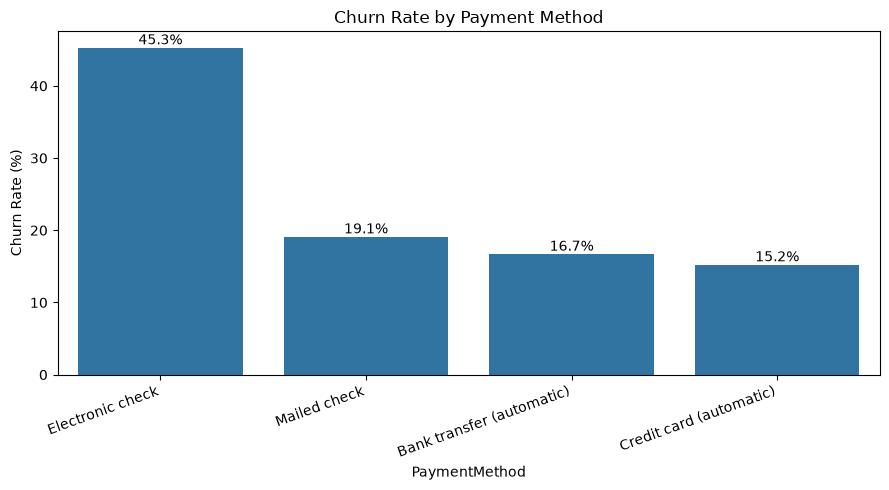

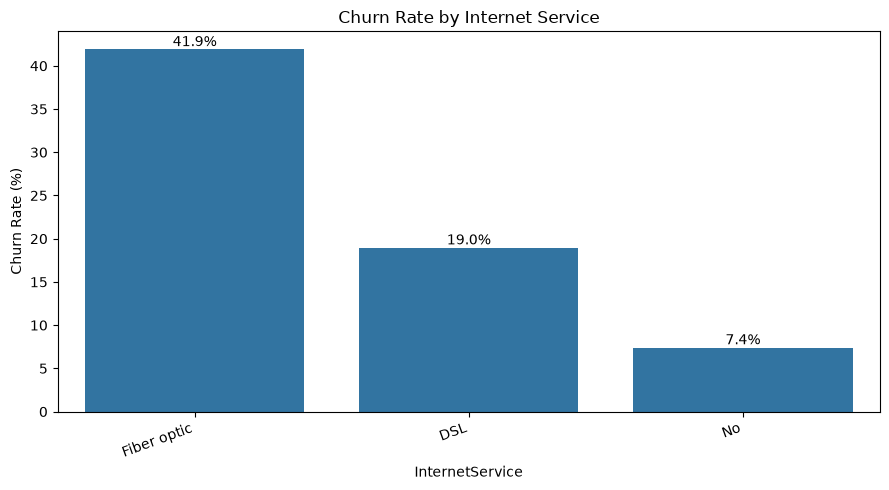

In [172]:
# Helper function for plotting churn rate by a categorical feature
def plot_churn_rate(feature, title=None, figsize=(9, 5)):
    summary = (
        df_cus.groupby(feature)["Churn_Flag"]
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )

    plt.figure(figsize=figsize)
    ax = sns.barplot(
        x=summary.index,
        y=summary.values
    )

    plt.title(title or f"Churn Rate by {feature}")
    plt.xlabel(feature)
    plt.ylabel("Churn Rate (%)")
    plt.xticks(rotation=20, ha="right")

    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f%%")

    plt.tight_layout()
    plt.show()

    return summary

tech_support_churn = plot_churn_rate(
    "TechSupport",
    "Churn Rate by Tech Support"
)

payment_churn = plot_churn_rate(
    "PaymentMethod",
    "Churn Rate by Payment Method"
)

internet_churn = plot_churn_rate(
    "InternetService",
    "Churn Rate by Internet Service"
)

In [173]:
# Group statistics calculation for monthly change 
charge_summary = df_cus.groupby("Churn")[
    "MonthlyCharges"
].agg(["count", "mean", "median"]).round(2)

print(charge_summary)

       count   mean  median
Churn                      
No      5174  61.27   64.43
Yes     1869  74.44   79.65


In [174]:
monthly_charge_churn = (
    df_cus.groupby("Monthly_Charge_Group", observed=False)["Churn_Flag"]
    .agg(Customers="count", Churned="sum", Churn_Rate="mean")
)

monthly_charge_churn["Churn_Rate"] = (
    monthly_charge_churn["Churn_Rate"] * 100
).round(2)

print(monthly_charge_churn)

                      Customers  Churned  Churn_Rate
Monthly_Charge_Group                                
$0–$40                     1838      214       11.64
$41–$70                    1622      388       23.92
$71–$100                   2681     1014       37.82
$100+                       902      253       28.05


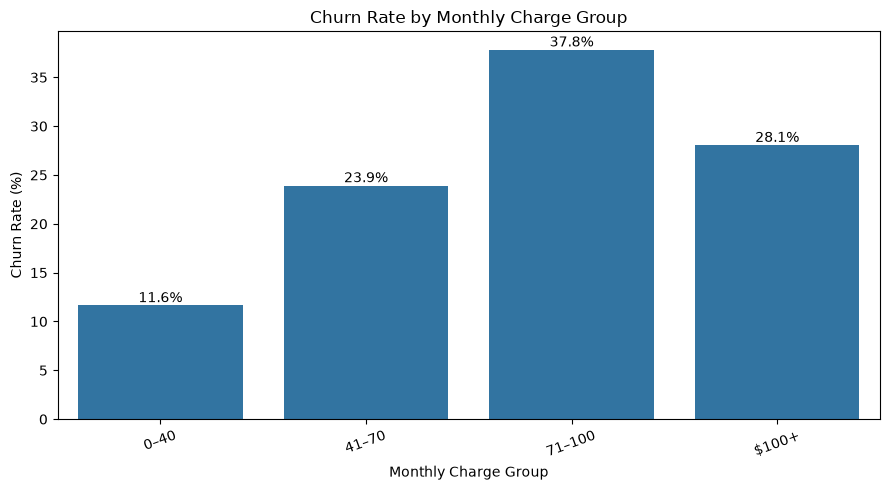

In [175]:
plt.figure(figsize=(9, 5))
ax = sns.barplot(
    data=monthly_charge_churn.reset_index(),
    x="Monthly_Charge_Group",
    y="Churn_Rate"
)

plt.title("Churn Rate by Monthly Charge Group")
plt.xlabel("Monthly Charge Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.tight_layout()
plt.show()

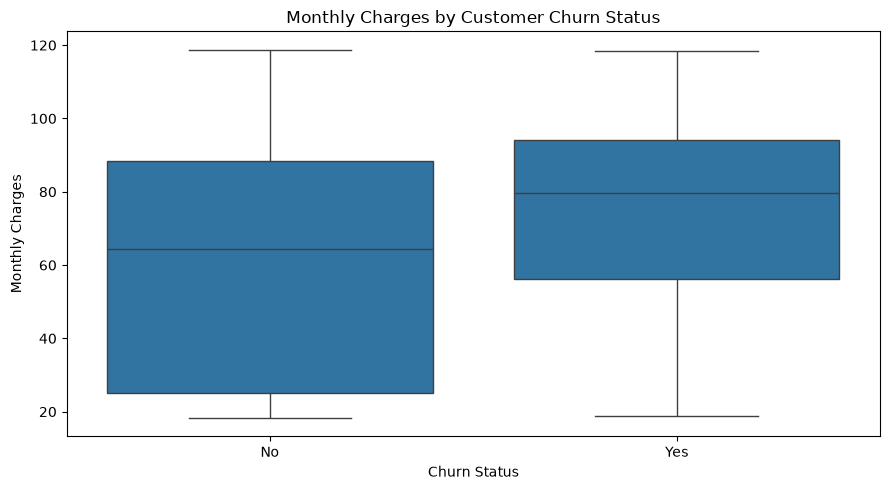

In [176]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_cus,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Customer Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

In [177]:
tenure_charge_churn = pd.pivot_table(
    df_cus,
    index="Tenure_Group",
    columns="Monthly_Charge_Group",
    values="Churn_Flag",
    aggfunc="mean",
    observed=False
) * 100

print(tenure_charge_churn.round(2))

Monthly_Charge_Group  $0–$40  $41–$70  $71–$100  $100+
Tenure_Group                                          
0-12 months            25.04    42.97     67.35  76.47
13-24 months            6.92    21.79     44.05  56.90
25-36 months            5.26     8.20     34.84  35.63
37-48 months            4.08    13.17     25.09  37.50
49-60 months            3.30     8.72     16.46  29.01
61-72 months            0.34     2.46      5.93  13.68


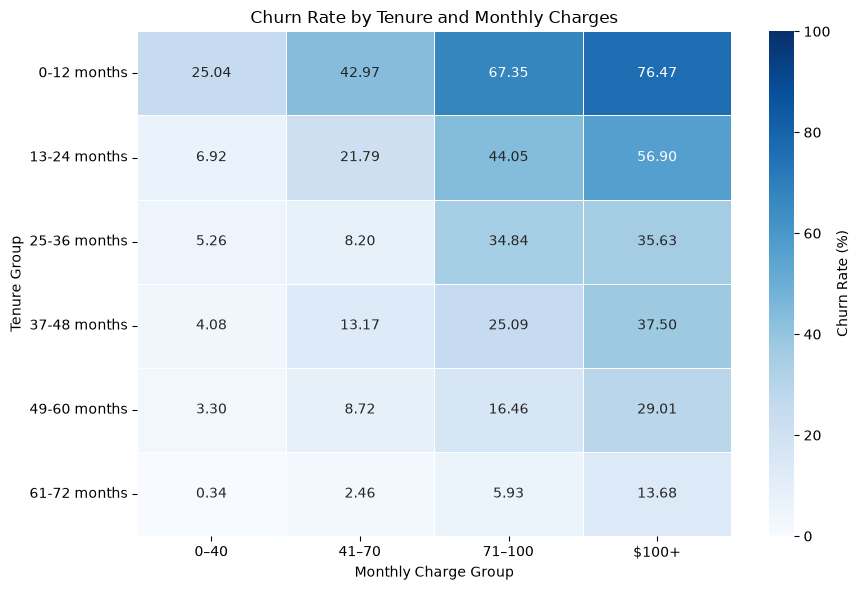

In [178]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    tenure_Group,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Churn Rate (%)"},
    vmin=0,
    vmax=100
)

plt.title("Churn Rate by Tenure and Monthly Charges")
plt.xlabel("Monthly Charge Group")
plt.ylabel("Tenure Group")
plt.tight_layout()
plt.show()

In [179]:
tenure_by_status = (
    df_cus.groupby("Churn")["tenure"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

display(tenure_by_status)

,count,mean,median,min,max
Churn,,,,,
No,5174,37.57,38.0,0,72
Yes,1869,17.98,10.0,1,72


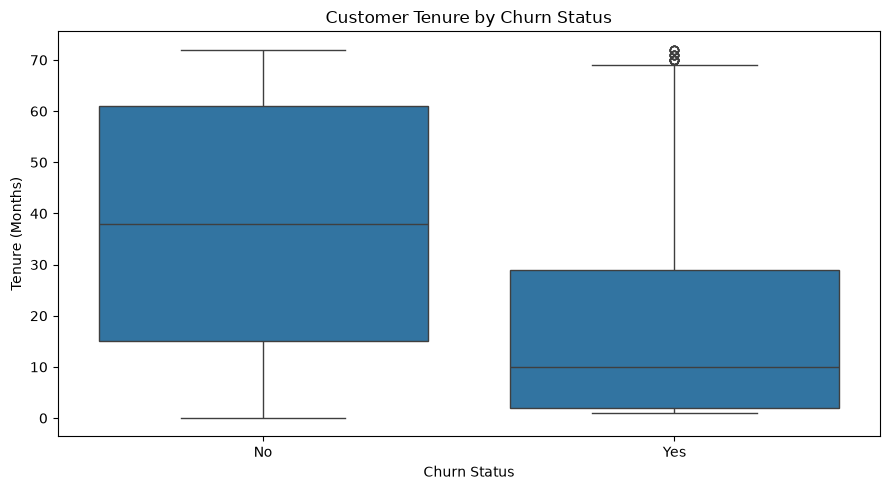

In [180]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_cus,
    x="Churn",
    y="tenure"
)

plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")
plt.tight_layout()
plt.show()

In [181]:
date_columns = [
    column for column in df_cus.columns
    if "date" in column.lower()
    or "signup" in column.lower()
    or "start" in column.lower()
]

print("Potential date columns:", date_columns)

if not date_columns:
    print("No signup/start-date column is available; use Tenure_Group instead of signup cohorts.")

Potential date columns: []
No signup/start-date column is available; use Tenure_Group instead of signup cohorts.


In [184]:
# Churn report
highest_contract = contract_summary["Churn_Rate"].idxmax()
highest_contract_rate = contract_summary["Churn_Rate"].max()

highest_tenure_group = tenure_summary["Churn_Rate"].idxmax()
highest_tenure_rate = tenure_summary["Churn_Rate"].max()

highest_payment = payment_churn.index[0]
highest_payment_rate = payment_churn.iloc[0]

highest_internet = internet_churn.index[0]
highest_internet_rate = internet_churn.iloc[0]

print("KEY RETENTION INSIGHTS")

print(f"Overall churn rate: {overall_churn_rate:.2f}%")
print(f"Highest-churn contract: {highest_contract} {highest_contract_rate:.2f}%")
print(f"Highest-churn tenure group: {highest_tenure_group} {highest_tenure_rate:.2f}%")
print(f"Highest-churn payment method: {highest_payment} {highest_payment_rate:.2f}%")
print(f"Highest-churn internet service: {highest_internet} {highest_internet_rate:.2f}%")

KEY RETENTION INSIGHTS
Overall churn rate: 26.54%
Highest-churn contract: Month-to-month 42.71%
Highest-churn tenure group: 0-12 months 47.44%
Highest-churn payment method: Electronic check 45.29%
Highest-churn internet service: Fiber optic 41.89%


In [183]:
output_file = "Telco_Customer_Churn_cleaned.csv"
df_cus.to_csv(output_file, index=False)

print(f"Cleaned dataset saved successfully as: {output_file}")
print(f"Final dataset shape: {df_cus.shape[0]:,} rows × {df_cus.shape[1]} columns")

Cleaned dataset saved successfully as: Customer_Churn_clean.csv
Final dataset shape: 7,043 rows × 24 columns
